# **KcBERT fine-tuning으로 KOTE 다중 라벨 감정 분류**

### 모델: KcBERT (`beomi/kcbert-base`)
- 한국어 뉴스 댓글/대댓글 약 8,900만 문장으로 토크나이저와 BERT를 처음부터 학습
- BERT-Base 구조 (12층, hidden 768, head 12), WordPiece vocab 30,000
- **최대 입력 길이 300 토큰** (BERT 기본 512가 아님)

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

from datasets import load_dataset
from transformers import AutoTokenizer

plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 깨짐 방지 (Windows)
plt.rcParams["axes.unicode_minus"] = False

In [10]:
DATA_DIR = Path("./data/KOTE")
MODEL_NAME = "beomi/kcbert-base"
NUM_LABELS = 44

print("DATA_DIR:", DATA_DIR.resolve())

DATA_DIR: D:\haewoon\KDT\12_NLP\data\kote


In [ ]:
# 데이터 불러오기
COLS = ["id", "text", "labels"]

train = load_dataset("csv", data_files=str(DATA_DIR / "train.tsv"), delimiter="\t", column_names=COLS, split="train")
validation = load_dataset("csv", data_files=str(DATA_DIR / "val.tsv"), delimiter="\t", column_names=COLS, split="train")
test = load_dataset("csv", data_files=str(DATA_DIR / "test.tsv"), delimiter="\t", column_names=COLS, split="train")

print(train)
print(validation)
print(test)
print(train[0])

Dataset({
    features: ['id', 'text', 'labels'],
    num_rows: 40000
})
Dataset({
    features: ['id', 'text', 'labels'],
    num_rows: 5000
})
Dataset({
    features: ['id', 'text', 'labels'],
    num_rows: 5000
})
{'id': 39087, 'text': '내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.', 'labels': '2,13,15,16,29,39'}


In [ ]:
# 라벨 확인 (7_PLM의 parse_label 방식)
# 감정이 1개뿐인 댓글은 '5'처럼 숫자 하나라서 int로 읽힐 수 있음 → str()로 감싼 뒤 split

def parse_label(value):
    return [int(x) for x in str(value).split(",")]

train_y = [parse_label(x) for x in train["labels"]]

num_per_comment = np.array([len(y) for y in train_y])
all_labels = [l for y in train_y for l in y]

print("라벨 번호 범위:", min(all_labels), "~", max(all_labels))
print("train에 등장한 라벨 종류 수:", len(set(all_labels)))
print(f"댓글당 감정 수: 평균 {num_per_comment.mean():.2f} / 최대 {num_per_comment.max()} / 1개인 댓글 {np.mean(num_per_comment == 1):.2%}")

라벨 번호 범위: 0 ~ 43
train에 등장한 라벨 종류 수: 44
댓글당 감정 수: 평균 7.91 / 최대 22 / 1개인 댓글 0.90%


In [ ]:
# 데이터 전처리

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer:", type(tokenizer).__name__)
print("vocab size:", tokenizer.vocab_size)
print("model_max_length:", tokenizer.model_max_length)   # 300 (BERT 기본 512가 아님)
print("CLS:", tokenizer.cls_token, tokenizer.cls_token_id)
print("SEP:", tokenizer.sep_token, tokenizer.sep_token_id)
print("PAD:", tokenizer.pad_token, tokenizer.pad_token_id)
print("UNK:", tokenizer.unk_token, tokenizer.unk_token_id)

Tokenizer: BertTokenizer
vocab size: 30000
model_max_length: 300
CLS: [CLS] 2
SEP: [SEP] 3
PAD: [PAD] 0
UNK: [UNK] 1


In [ ]:
# 댓글 몇 개 토큰화해 확인

for i in range(3):
    text = train[i]["text"]
    enc = tokenizer(text, truncation=True, max_length=300)
    print("원문:", text)
    print("토큰:", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
    print("길이:", len(enc["input_ids"]))
    print()

원문: 내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.
토큰: ['[CLS]', '내가', '톰', '##행', '##크', '##스를', '좋아', '##하긴', '했나', '##보다', '.', '.', '.', '초기', '영화', '빼고는', '다', '봤', '##네', '.', '[SEP]']
길이: 21

원문: 정말 상상을 초월하는 무개념 진상들 상대하다 우울증, 공항장애 걸리는 공무원 많아요 ㅠ 생각보다 스트레스 심한 직업군이라는 생각입니다.
토큰: ['[CLS]', '정말', '상상', '##을', '초월', '##하는', '무개념', '진상', '##들', '상대', '##하다', '우울증', ',', '공항', '##장애', '걸리는', '공무원', '많아요', '[UNK]', '생각보다', '스트레스', '심한', '직업', '##군이', '##라는', '생각', '##입니다', '.', '[SEP]']
길이: 29

원문: 새로운 세상과 조우한 자의 어린아이 같은 반응, 어쩌면 회복된 것은 눈이 아닌 순수함일지도 모르겠습니다. 그걸 가능케 한 사랑에 경의를 표합니다.
토큰: ['[CLS]', '새로운', '세상', '##과', '조', '##우한', '자의', '어린아이', '같은', '반응', ',', '어쩌면', '회복', '##된', '것은', '눈이', '아닌', '순수', '##함', '##일지', '##도', '모르겠', '##습니다', '.', '그걸', '가능', '##케', '한', '사랑', '##에', '경', '##의를', '표', '##합니다', '.', '[SEP]']
길이: 36



In [ ]:
# KcBERT 정제 함수 (clean)
# KcBERT 공식 저장소(github.com/Beomi/KcBERT)의 전처리 함수
# 사전학습 때 같은 정제를 했으므로 fine-tuning 데이터에도 적용 권장

import emoji
from soynlp.normalizer import repeat_normalize

emojis = "".join(emoji.EMOJI_DATA.keys())
pattern = re.compile(f"[^ .,?!/@$%~％·∼()\x00-\x7Fㄱ-ㅣ가-힣{emojis}]+")
url_pattern = re.compile(
    r"https?:\/\/(www\.)?[-a-zA-Z0-9@:%._\+~#=]{1,256}\.[a-zA-Z0-9()]{1,6}\b([-a-zA-Z0-9()@:%_\+.~#?&//=]*)"
)

def clean(x):
    x = pattern.sub(" ", x)                    # 허용 문자 외 제거
    x = emoji.replace_emoji(x, replace="")     # 이모지 제거
    x = url_pattern.sub("", x)                 # URL 제거
    x = x.strip()
    x = repeat_normalize(x, num_repeats=2)     # ㅋㅋㅋㅋ → ㅋㅋ
    return x

for i in [0, 1]:
    print("원문 :", train[i]["text"])
    print("clean:", clean(train[i]["text"]))
    print()

원문 : 내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.
clean: 내가 톰행크스를 좋아하긴 했나보다... 초기 영화 빼고는 다 봤네.

원문 : 정말 상상을 초월하는 무개념 진상들 상대하다 우울증, 공항장애 걸리는 공무원 많아요 ㅠ 생각보다 스트레스 심한 직업군이라는 생각입니다.
clean: 정말 상상을 초월하는 무개념 진상들 상대하다 우울증, 공항장애 걸리는 공무원 많아요 ㅠ 생각보다 스트레스 심한 직업군이라는 생각입니다.



In [ ]:
# 토큰 길이 분포로 max_length 정하기
# np.percentile 사용
# 길이 측정에 CLS, SEP 포함

def token_lengths(texts):
    enc = tokenizer(list(texts), add_special_tokens=True, truncation=False)
    return np.array([len(ids) for ids in enc["input_ids"]]), enc["input_ids"]

raw_lens, raw_ids = token_lengths(train["text"])
clean_texts = [clean(t) for t in train["text"]]   # 아래 [UNK] 분석에서도 재사용
clean_lens, clean_ids = token_lengths(clean_texts)

for name, lens in [("원문", raw_lens), ("clean", clean_lens)]:
    print(f"[{name}] 평균 {lens.mean():.1f} | 중앙값 {np.median(lens):.0f} | "
          f"95% {np.percentile(lens, 95):.0f} | 99% {np.percentile(lens, 99):.0f} | 최대 {lens.max()}")

print()
for L in [64, 96, 128, 160, 256, 300]:
    print(f"max_length={L:>3}: 잘리는 댓글 {(clean_lens > L).mean() * 100:5.2f}% ({(clean_lens > L).sum()}개)")

[원문] 평균 28.6 | 중앙값 22 | 95% 67 | 99% 111 | 최대 245
[clean] 평균 28.4 | 중앙값 22 | 95% 67 | 99% 111 | 최대 245

max_length= 64: 잘리는 댓글  5.73% (2294개)
max_length= 96: 잘리는 댓글  1.79% (715개)
max_length=128: 잘리는 댓글  0.45% (180개)
max_length=160: 잘리는 댓글  0.11% (45개)
max_length=256: 잘리는 댓글  0.00% (0개)
max_length=300: 잘리는 댓글  0.00% (0개)


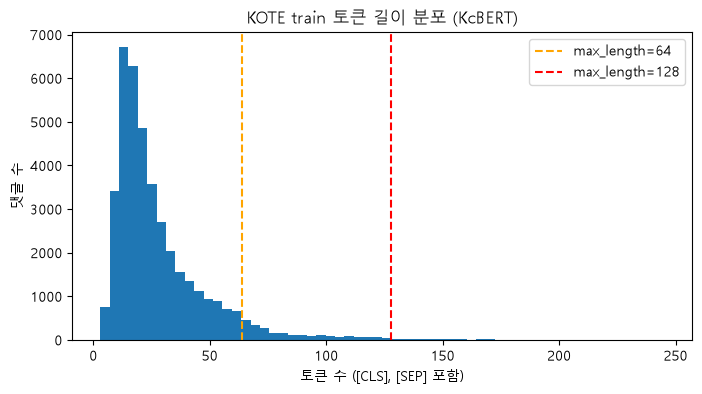

In [17]:
plt.figure(figsize=(8, 4))
plt.hist(clean_lens, bins=60)
for L, c in [(64, "orange"), (128, "red")]:
    plt.axvline(L, color=c, linestyle="--", label=f"max_length={L}")
plt.xlabel("토큰 수 ([CLS], [SEP] 포함)")
plt.ylabel("댓글 수")
plt.title("KOTE train 토큰 길이 분포 (KcBERT)")
plt.legend()
plt.show()

In [ ]:
# UNK 분석

unk_id = tokenizer.unk_token_id
for name, ids in [("원문", raw_ids), ("clean", clean_ids)]:
    n_unk = sum(x.count(unk_id) for x in ids)
    n_tok = sum(len(x) for x in ids)
    print(f"[{name}] UNK 토큰 비율 {n_unk / n_tok:.2%} | UNK 포함 댓글 {np.mean([unk_id in x for x in ids]):.2%}")

# 어떤 단어가 UNK가 되는지
# 띄어쓰기 단위 단어의 등장 횟수를 센 뒤, 고유 단어만 한 번에 토큰화
word_counts = Counter(w for t in clean_texts for w in t.split())
unique_words = list(word_counts)
word_ids = tokenizer(unique_words, add_special_tokens=False)["input_ids"]
unk_words = Counter({w: word_counts[w] for w, ids in zip(unique_words, word_ids) if unk_id in ids})

print("\nUNK가 되는 단어 상위 15개:")
print(unk_words.most_common(15))

print("\n자모 표현 토큰화:")
print([(w, tokenizer.tokenize(w)) for w in ["ㅠㅠ", "ㅜㅜ", "ㅡㅡ", "ㅋㅋ", "ㅎㅎ", "ㄷㄷ"]])

[원문] UNK 토큰 비율 0.55% | UNK 포함 댓글 11.13%
[clean] UNK 토큰 비율 0.53% | UNK 포함 댓글 10.87%

UNK가 되는 단어 상위 15개:
[('ㅠㅠ', 715), ('ㅠ', 264), ('ㅜㅜ', 199), ('ㅡㅡ', 121), ('ㅠㅠㅠ', 95), ('ㅜ', 65), ('ㅡ', 39), ('->', 15), ('ㅜㅜㅜ', 15), ('ㅜㅠ', 13), ('ㅠ.ㅠ', 13), ('>', 13), ('ㅠㅜ', 12), ('&', 11), ('다행이다ㅠㅠ', 8)]

자모 표현 토큰화:
[('ㅠㅠ', ['[UNK]']), ('ㅜㅜ', ['[UNK]']), ('ㅡㅡ', ['[UNK]']), ('ㅋㅋ', ['ㅋㅋ']), ('ㅎㅎ', ['ㅎㅎ']), ('ㄷㄷ', ['ㄷㄷ'])]


In [ ]:
# KcBERT vocab에 모음 자모(ㅏ~ㅣ)가 들어 있는지 확인

vocab = tokenizer.get_vocab()
vowel_tokens = [t for t in vocab if any("ㅏ" <= ch <= "ㅣ" for ch in t.replace("##", ""))]
print("모음 자모가 들어간 토큰 수:", len(vowel_tokens))
print("'ㅠ' in vocab:", "ㅠ" in vocab, "| 'ㅋ' in vocab:", "ㅋ" in vocab)

모음 자모가 들어간 토큰 수: 0
'ㅠ' in vocab: False | 'ㅋ' in vocab: True


In [ ]:
# 정답 라벨을 multi-hot 벡터로 변환

from sklearn.preprocessing import MultiLabelBinarizer
import torch

LABEL_NAMES = [
    '불평/불만', '환영/호의', '감동/감탄', '지긋지긋', '고마움', '슬픔', '화남/분노', '존경', '기대감', '우쭐댐/무시함',
    '안타까움/실망', '비장함', '의심/불신', '뿌듯함', '편안/쾌적', '신기함/관심', '아껴주는', '부끄러움', '공포/무서움', '절망',
    '한심함', '역겨움/징그러움', '짜증', '어이없음', '없음', '패배/자기혐오', '귀찮음', '힘듦/지침', '즐거움/신남', '깨달음',
    '죄책감', '증오/혐오', '흐뭇함(귀여움/예쁨)', '당황/난처', '경악', '부담/안_내킴', '서러움', '재미없음', '불쌍함/연민', '놀람',
    '행복', '불안/걱정', '기쁨', '안심/신뢰',
]
assert len(LABEL_NAMES) == NUM_LABELS

validation_y = [parse_label(x) for x in validation["labels"]]
test_y = [parse_label(x) for x in test["labels"]]

enc = MultiLabelBinarizer(classes=list(range(NUM_LABELS)))
enc.fit(train_y)   # train/val/test 모두 같은 encoder로 transform

train_labels = torch.tensor(enc.transform(train_y), dtype=torch.float32)
validation_labels = torch.tensor(enc.transform(validation_y), dtype=torch.float32)
test_labels = torch.tensor(enc.transform(test_y), dtype=torch.float32)

print("labels shape:", train_labels.shape, validation_labels.shape, test_labels.shape)
print("원래 label:", train_y[0])
print("multi-hot :", train_labels[0])
print("감정 이름 :", [LABEL_NAMES[i] for i in train_y[0]])

labels shape: torch.Size([40000, 44]) torch.Size([5000, 44]) torch.Size([5000, 44])
원래 label: [2, 13, 15, 16, 29, 39]
multi-hot : tensor([0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 1., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 0., 0., 0.])
감정 이름 : ['감동/감탄', '뿌듯함', '신기함/관심', '아껴주는', '깨달음', '놀람']


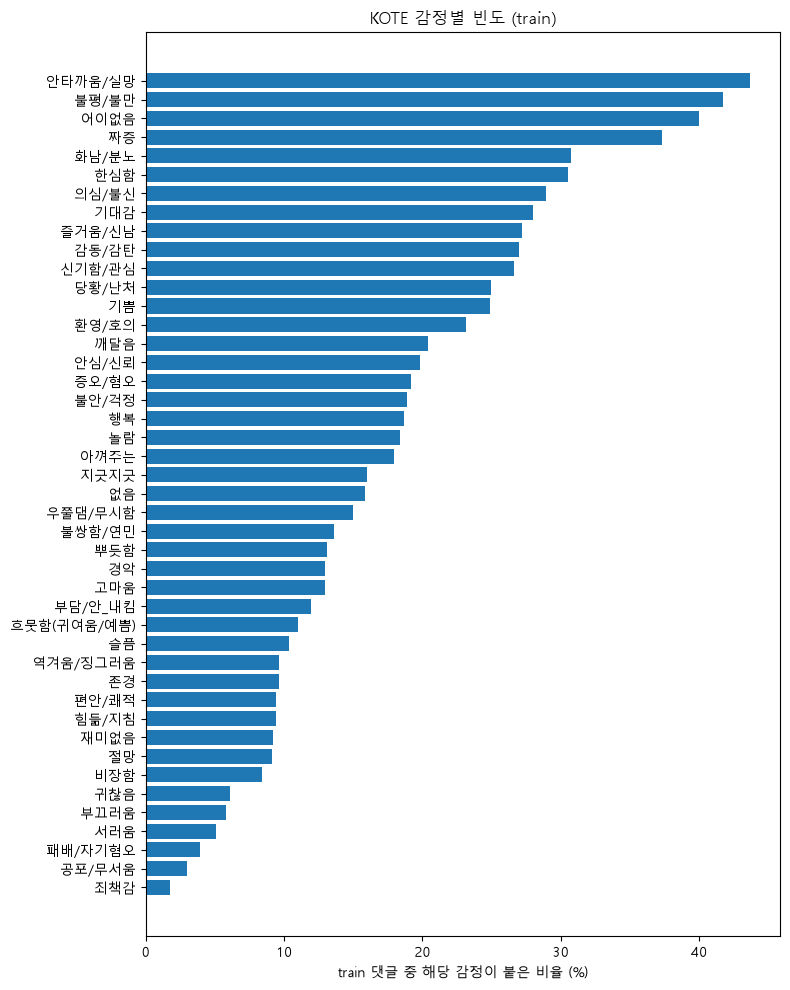

가장 드문 감정 5개: [('죄책감', 698), ('공포/무서움', 1194), ('패배/자기혐오', 1581), ('서러움', 2031), ('부끄러움', 2329)]
가장 흔한 감정 5개: [('안타까움/실망', 17465), ('불평/불만', 16696), ('어이없음', 15996), ('짜증', 14930), ('화남/분노', 12299)]


In [ ]:
# 감정별 등장 빈도 (train)
# 희귀 감정 확인

label_freq = train_labels.sum(dim=0).numpy()
order = np.argsort(label_freq)

plt.figure(figsize=(8, 10))
plt.barh([LABEL_NAMES[i] for i in order], label_freq[order] / len(train_labels) * 100)
plt.xlabel("train 댓글 중 해당 감정이 붙은 비율 (%)")
plt.title("KOTE 감정별 빈도 (train)")
plt.tight_layout()
plt.show()

print("가장 드문 감정 5개:", [(LABEL_NAMES[i], int(label_freq[i])) for i in order[:5]])
print("가장 흔한 감정 5개:", [(LABEL_NAMES[i], int(label_freq[i])) for i in order[::-1][:5]])

In [ ]:
# 토큰화 (encode_texts)

MAX_LEN = 128

def encode_texts(texts, labels, tokenizer, max_len=MAX_LEN):
    texts = [clean("" if x is None else str(x)) for x in texts]
    encoded = tokenizer(
        texts,
        padding="max_length",
        add_special_tokens=True,
        truncation=True,
        max_length=max_len,
        return_tensors="pt",
    )
    return encoded["input_ids"], encoded["attention_mask"], labels.to(torch.float32)

train_inputs, train_masks, train_labels = encode_texts(train["text"], train_labels, tokenizer)
validation_inputs, validation_masks, validation_labels = encode_texts(validation["text"], validation_labels, tokenizer)
test_inputs, test_masks, test_labels = encode_texts(test["text"], test_labels, tokenizer)

print("input_ids     :", train_inputs.shape, validation_inputs.shape, test_inputs.shape)
print("attention_mask:", train_masks.shape)
print("labels        :", train_labels.shape, train_labels.dtype)

input_ids     : torch.Size([40000, 128]) torch.Size([5000, 128]) torch.Size([5000, 128])
attention_mask: torch.Size([40000, 128])
labels        : torch.Size([40000, 44]) torch.float32


In [ ]:
# 토큰화가 제대로 됐는지 되돌려서 확인

ids = train_inputs[1]
mask = train_masks[1]
n_real = int(mask.sum())

print("실제 토큰 수:", n_real, "/ PAD 수:", MAX_LEN - n_real)
print(tokenizer.convert_ids_to_tokens(ids[:n_real]))
print("decode:", tokenizer.decode(ids[:n_real], skip_special_tokens=True))
print("PAD 위치 mask 값:", mask[n_real:n_real + 5].tolist(), "| PAD id:", ids[n_real:n_real + 5].tolist())

실제 토큰 수: 29 / PAD 수: 99
['[CLS]', '정말', '상상', '##을', '초월', '##하는', '무개념', '진상', '##들', '상대', '##하다', '우울증', ',', '공항', '##장애', '걸리는', '공무원', '많아요', '[UNK]', '생각보다', '스트레스', '심한', '직업', '##군이', '##라는', '생각', '##입니다', '.', '[SEP]']
decode: 정말 상상을 초월하는 무개념 진상들 상대하다 우울증, 공항장애 걸리는 공무원 많아요 생각보다 스트레스 심한 직업군이라는 생각입니다.
PAD 위치 mask 값: [0, 0, 0, 0, 0] | PAD id: [0, 0, 0, 0, 0]


In [24]:
import random
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.xpu.is_available():
    DEVICE = torch.device("xpu")
else:
    DEVICE = torch.device("cpu")

print(DEVICE)

cuda


In [ ]:
# 데이터셋

BATCH_SIZE = 32

train_data = TensorDataset(train_inputs, train_masks, train_labels)
validation_data = TensorDataset(validation_inputs, validation_masks, validation_labels)
test_data = TensorDataset(test_inputs, test_masks, test_labels)

# 데이터로더

train_dataloader = DataLoader(train_data, sampler=RandomSampler(train_data), batch_size=BATCH_SIZE)
validation_dataloader = DataLoader(validation_data, sampler=SequentialSampler(validation_data), batch_size=BATCH_SIZE)
test_dataloader = DataLoader(test_data, sampler=SequentialSampler(test_data), batch_size=BATCH_SIZE)

print("배치 수:", len(train_dataloader), len(validation_dataloader), len(test_dataloader))

input_ids, attention_mask, labels = next(iter(train_dataloader))
print("input_ids     :", input_ids.shape, input_ids.dtype)
print("attention_mask:", attention_mask.shape, attention_mask.dtype)
print("labels        :", labels.shape, labels.dtype)

배치 수: 1250 157 157
input_ids     : torch.Size([32, 128]) torch.int64
attention_mask: torch.Size([32, 128]) torch.int64
labels        : torch.Size([32, 44]) torch.float32


In [ ]:
# 모델

from transformers import AutoModelForSequenceClassification

# problem_type="multi_label_classification" → 모델 내부에서 BCEWithLogitsLoss를 자동으로 사용
# 이때 labels는 반드시 float (앞에서 float32로 만든 이유)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
)
model.to(DEVICE)

print(type(model).__name__)
print("num_labels:", model.config.num_labels, "| problem_type:", model.config.problem_type)
print("분류 head:", model.classifier)
print(f"전체 파라미터: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

d:\haewoon\KDT\12_NLP\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 994.05it/s] 
[transformers] BertForSequenceClassification LOAD REPORT from: beomi/kcbert-base
K

BertForSequenceClassification
num_labels: 44 | problem_type: multi_label_classification
분류 head: Linear(in_features=768, out_features=44, bias=True)
전체 파라미터: 109.0M


In [ ]:
# optimizer, scheduler 설정

from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

EPOCHS = 5
LEARNING_RATE = 2e-5
PATIENCE = 2          # val macro F1이 2 epoch 연속 좋아지지 않으면 중단
THRESHOLD = 0.3       # KOTE 제작자와 같은 기준 (threshold 변화는 4단계에서 따로 확인)

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
total_steps = len(train_dataloader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps,
)

print("전체 학습 step:", total_steps, "| warmup step:", int(total_steps * 0.1))

전체 학습 step: 6250 | warmup step: 625


In [ ]:
# 평가 함수

import time
import datetime
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score, hamming_loss

def format_time(elapsed):
    return str(datetime.timedelta(seconds=int(round(elapsed))))

def multi_label_metrics(probs, labels, threshold=THRESHOLD):
    y_true = np.asarray(labels).astype(int)
    y_pred = (np.asarray(probs) >= threshold).astype(int)
    return {
        "f1_micro": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision_micro": precision_score(y_true, y_pred, average="micro", zero_division=0),
        "recall_micro": recall_score(y_true, y_pred, average="micro", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
        "avg_pred_labels": y_pred.sum(axis=1).mean(),    # 댓글당 예측한 감정 수 (정답 평균은 약 7.9)
    }

def evaluate(model, dataloader, device, threshold=THRESHOLD):
    model.eval()
    total_loss = 0.0
    all_probs, all_labels = [], []

    for batch in tqdm(dataloader, leave=False):
        input_ids, attention_mask, labels = [x.to(device) for x in batch]

        with torch.inference_mode():
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)

        total_loss += outputs.loss.item()
        all_probs.append(torch.sigmoid(outputs.logits).cpu())
        all_labels.append(labels.cpu())

    probs = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()

    metrics = multi_label_metrics(probs, labels, threshold)
    metrics["loss"] = total_loss / len(dataloader)
    return metrics, probs, labels

In [ ]:
# 모델 학습

MODEL_DIR = Path("./model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
BEST_PATH = MODEL_DIR / "kcbert_kote_best.pt"

history = {"train_loss": [], "val_loss": [], "val_f1_micro": [], "val_f1_macro": []}
best_f1_macro = -1.0
best_epoch = 0
no_improve = 0

for epoch in range(1, EPOCHS + 1):
    print(f"\n======== Epoch {epoch} / {EPOCHS} ========")
    start = time.time()
    model.train()
    total_loss = 0.0

    for batch in tqdm(train_dataloader):
        input_ids, attention_mask, labels = [x.to(DEVICE) for x in batch]

        optimizer.zero_grad(set_to_none=True)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

    train_loss = total_loss / len(train_dataloader)
    val_metrics, _, _ = evaluate(model, validation_dataloader, DEVICE)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["val_f1_micro"].append(val_metrics["f1_micro"])
    history["val_f1_macro"].append(val_metrics["f1_macro"])

    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_metrics['loss']:.4f} | Time: {format_time(time.time() - start)}")
    print(f"Val F1 micro: {val_metrics['f1_micro']:.4f} | macro: {val_metrics['f1_macro']:.4f} | "
          f"댓글당 예측 감정 수: {val_metrics['avg_pred_labels']:.2f}")

    if val_metrics["f1_macro"] > best_f1_macro:
        best_f1_macro = val_metrics["f1_macro"]
        best_epoch = epoch
        no_improve = 0
        torch.save(model.state_dict(), BEST_PATH)
        print(f"  -> best 갱신, 저장: {BEST_PATH}")
    else:
        no_improve += 1
        print(f"  -> 개선 없음 ({no_improve}/{PATIENCE})")
        if no_improve >= PATIENCE:
            print("조기종료")
            break

print(f"\nBest epoch: {best_epoch} | Best val macro F1: {best_f1_macro:.4f}")


======== Epoch 1 / 5 ========


100%|██████████| 1250/1250 [10:12<00:00,  2.04it/s]


Train Loss: 0.3899 | Val Loss: 0.3120 | Time: 0:10:36
Val F1 micro: 0.6105 | macro: 0.4805 | 댓글당 예측 감정 수: 9.44
  -> best 갱신, 저장: model\kcbert_kote_best.pt

======== Epoch 2 / 5 ========


100%|██████████| 1250/1250 [10:09<00:00,  2.05it/s]


Train Loss: 0.2972 | Val Loss: 0.2973 | Time: 0:10:34
Val F1 micro: 0.6266 | macro: 0.5198 | 댓글당 예측 감정 수: 9.77
  -> best 갱신, 저장: model\kcbert_kote_best.pt

======== Epoch 3 / 5 ========


...

Train Loss: 0.2704 | Val Loss: 0.2920 | Time: 0:10:33
Val F1 micro: 0.6340 | macro: 0.5222 | 댓글당 예측 감정 수: 9.03
  -> best 갱신, 저장: model\kcbert_kote_best.pt

======== Epoch 4 / 5 ========


100%|██████████| 1250/1250 [10:07<00:00,  2.06it/s]


Train Loss: 0.2533 | Val Loss: 0.2927 | Time: 0:10:32
Val F1 micro: 0.6342 | macro: 0.5304 | 댓글당 예측 감정 수: 9.15
  -> best 갱신, 저장: model\kcbert_kote_best.pt

======== Epoch 5 / 5 ========


100%|██████████| 1250/1250 [10:14<00:00,  2.03it/s]


Train Loss: 0.2421 | Val Loss: 0.2932 | Time: 0:10:42
Val F1 micro: 0.6343 | macro: 0.5331 | 댓글당 예측 감정 수: 9.31
  -> best 갱신, 저장: model\kcbert_kote_best.pt

Best epoch: 5 | Best val macro F1: 0.5331


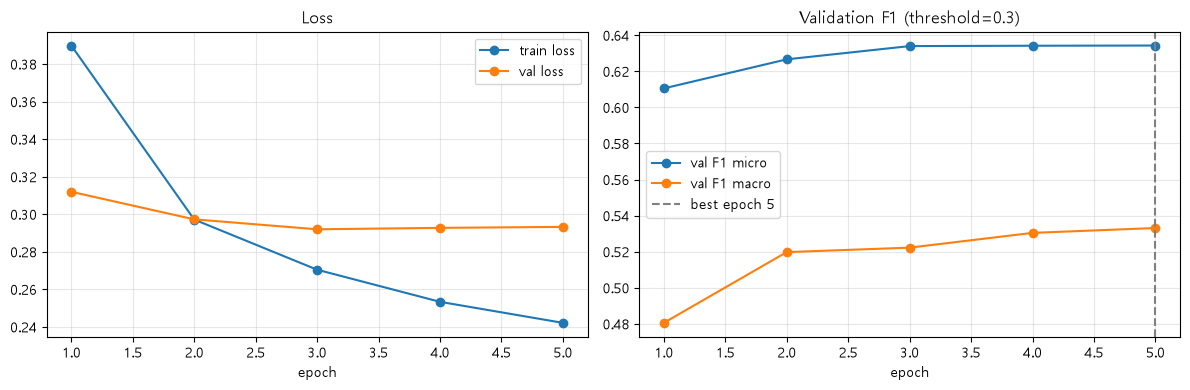

In [30]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, history["train_loss"], marker="o", label="train loss")
axes[0].plot(epochs_ran, history["val_loss"], marker="o", label="val loss")
axes[0].set_xlabel("epoch")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history["val_f1_micro"], marker="o", label="val F1 micro")
axes[1].plot(epochs_ran, history["val_f1_macro"], marker="o", label="val F1 macro")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch {best_epoch}")
axes[1].set_xlabel("epoch")
axes[1].set_title(f"Validation F1 (threshold={THRESHOLD})")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# best 모델 불러오기

BEST_PATH = Path("./model") / "kcbert_kote_best.pt"

best_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
)
best_model.load_state_dict(torch.load(BEST_PATH, map_location="cpu"))
best_model.to(DEVICE)
best_model.eval()

val_metrics, val_probs, val_true = evaluate(best_model, validation_dataloader, DEVICE)
print(f"best 모델 val 성능 (threshold={THRESHOLD})")
for k, v in val_metrics.items():
    print(f"  {k}: {v:.4f}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 649.62it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: beomi/kcbert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoin

best 모델 val 성능 (threshold=0.3)
  f1_micro: 0.6343
  f1_macro: 0.5331
  precision_micro: 0.5852
  recall_micro: 0.6924
  hamming_loss: 0.1428
  avg_pred_labels: 9.3136
  loss: 0.2932


In [ ]:
# 성능 평가

thresholds = np.round(np.arange(0.05, 0.71, 0.05), 2)
rows = []
for th in thresholds:
    m = multi_label_metrics(val_probs, val_true, threshold=th)
    rows.append({"threshold": th, **m})
th_df = pd.DataFrame(rows).set_index("threshold")

best_th_macro = th_df["f1_macro"].idxmax()
best_th_micro = th_df["f1_micro"].idxmax()

print(f"val 정답 감정 수 평균: {val_true.sum(axis=1).mean():.2f}")
print(f"val macro F1 최대: threshold={best_th_macro} → {th_df.loc[best_th_macro, 'f1_macro']:.4f}")
print(f"val micro F1 최대: threshold={best_th_micro} → {th_df.loc[best_th_micro, 'f1_micro']:.4f}")
print(f"threshold=0.3     : macro {th_df.loc[0.3, 'f1_macro']:.4f} / micro {th_df.loc[0.3, 'f1_micro']:.4f}")
th_df[["f1_micro", "f1_macro", "precision_micro", "recall_micro", "avg_pred_labels"]].round(4)

val 정답 감정 수 평균: 7.87
val macro F1 최대: threshold=0.25 → 0.5375
val micro F1 최대: threshold=0.3 → 0.6343
threshold=0.3     : macro 0.5331 / micro 0.6343


,f1_micro,f1_macro,precision_micro,recall_micro,avg_pred_labels
threshold,,,,,
0.05,0.4924,0.4432,0.3335,0.9406,22.2024
0.10,0.5612,0.5002,0.4123,0.8784,16.7704
0.15,0.5974,0.5247,0.4683,0.8247,13.8640
0.20,0.6167,0.5334,0.5119,0.7755,11.9240
0.25,0.6297,0.5375,0.5512,0.7342,10.4864
0.30,0.6343,0.5331,0.5852,0.6924,9.3136
0.35,0.6338,0.5232,0.6163,0.6522,8.3302
0.40,0.6297,0.5105,0.6462,0.6140,7.4806
0.45,0.6207,0.4919,0.6744,0.5750,6.7118


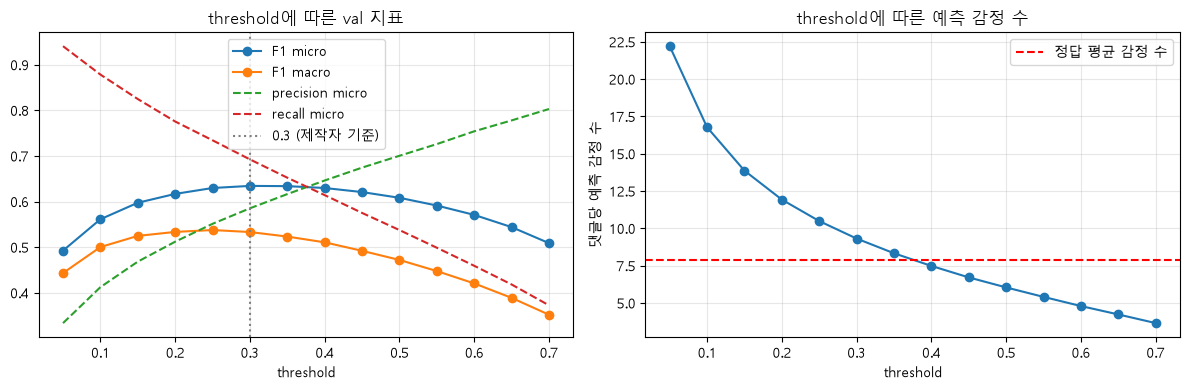

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(th_df.index, th_df["f1_micro"], marker="o", label="F1 micro")
axes[0].plot(th_df.index, th_df["f1_macro"], marker="o", label="F1 macro")
axes[0].plot(th_df.index, th_df["precision_micro"], linestyle="--", label="precision micro")
axes[0].plot(th_df.index, th_df["recall_micro"], linestyle="--", label="recall micro")
axes[0].axvline(0.3, color="gray", linestyle=":", label="0.3 (제작자 기준)")
axes[0].set_xlabel("threshold")
axes[0].set_title("threshold에 따른 val 지표")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(th_df.index, th_df["avg_pred_labels"], marker="o")
axes[1].axhline(val_true.sum(axis=1).mean(), color="red", linestyle="--", label="정답 평균 감정 수")
axes[1].set_xlabel("threshold")
axes[1].set_ylabel("댓글당 예측 감정 수")
axes[1].set_title("threshold에 따른 예측 감정 수")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 2) test 평가 (한 번만)
- 지금까지 test는 학습, 조기종료, threshold 선택 어디에도 쓰지 않음
- **"전부 예측" 기준선**: 학습 없이 44개 감정을 모두 있다고 찍었을 때의 F1 → 모델이 최소한 이보다는 나아야 의미가 있음

In [34]:
test_metrics, test_probs, test_true = evaluate(best_model, test_dataloader, DEVICE, threshold=0.3)
test_metrics_valth = multi_label_metrics(test_probs, test_true, threshold=best_th_macro)
baseline_all = multi_label_metrics(np.ones_like(test_true), test_true, threshold=0.5)

print("[test] threshold=0.3 (제작자 기준)")
for k, v in test_metrics.items():
    print(f"  {k}: {v:.4f}")

print(f"\n[test] threshold={best_th_macro} (val macro F1 기준으로 선택)")
print(f"  f1_micro: {test_metrics_valth['f1_micro']:.4f} | f1_macro: {test_metrics_valth['f1_macro']:.4f}")

print("\n[test] 전부 예측 기준선")
print(f"  f1_micro: {baseline_all['f1_micro']:.4f} | f1_macro: {baseline_all['f1_macro']:.4f}")

[test] threshold=0.3 (제작자 기준)
  f1_micro: 0.6361
  f1_macro: 0.5368
  precision_micro: 0.5897
  recall_micro: 0.6904
  hamming_loss: 0.1424
  avg_pred_labels: 9.2842
  loss: 0.2944

[test] threshold=0.25 (val macro F1 기준으로 선택)
  f1_micro: 0.6315 | f1_macro: 0.5403

[test] 전부 예측 기준선
  f1_micro: 0.3054 | f1_macro: 0.2921


In [35]:
# test 확률을 파일로 저장 → 노트북을 다시 열어도 test를 다시 추론하지 않고 분석 가능
RESULT_DIR = Path("./results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)
np.save(RESULT_DIR / "kcbert_test_probs.npy", test_probs)
np.save(RESULT_DIR / "kcbert_val_probs.npy", val_probs)
print("저장:", (RESULT_DIR / "kcbert_test_probs.npy").resolve())

저장: D:\haewoon\KDT\12_NLP\results\kcbert_test_probs.npy


### 3) 감정별 classification report (test, threshold=0.3)
- `support`: test에서 그 감정이 붙은 댓글 수
- 감정별 F1과 **train 빈도**를 함께 보면 희귀 감정에서 성능이 떨어지는지 확인 가능 (LSTM 결과와 비교 포인트)

In [36]:
from sklearn.metrics import classification_report

test_pred = (test_probs >= 0.3).astype(int)
report = classification_report(
    test_true.astype(int), test_pred,
    target_names=LABEL_NAMES, zero_division=0, output_dict=True,
)

report_df = pd.DataFrame(report).T.loc[LABEL_NAMES]
report_df["train_freq(%)"] = label_freq / len(train_y) * 100
report_df = report_df.sort_values("f1-score")
report_df[["precision", "recall", "f1-score", "support", "train_freq(%)"]].round(3)

,precision,recall,f1-score,support,train_freq(%)
죄책감,0.000,0.000,0.000,84.0,1.745000
부끄러움,0.354,0.056,0.096,306.0,5.822000
패배/자기혐오,0.369,0.149,0.212,208.0,3.952000
귀찮음,0.405,0.169,0.238,290.0,6.070000
서러움,0.326,0.224,0.266,263.0,5.078000
부담/안_내킴,0.390,0.251,0.305,606.0,11.920000
공포/무서움,0.538,0.256,0.347,164.0,2.985000
절망,0.457,0.347,0.395,472.0,9.130000
힘듦/지침,0.471,0.391,0.427,473.0,9.422000
우쭐댐/무시함,0.418,0.464,0.440,743.0,15.005000


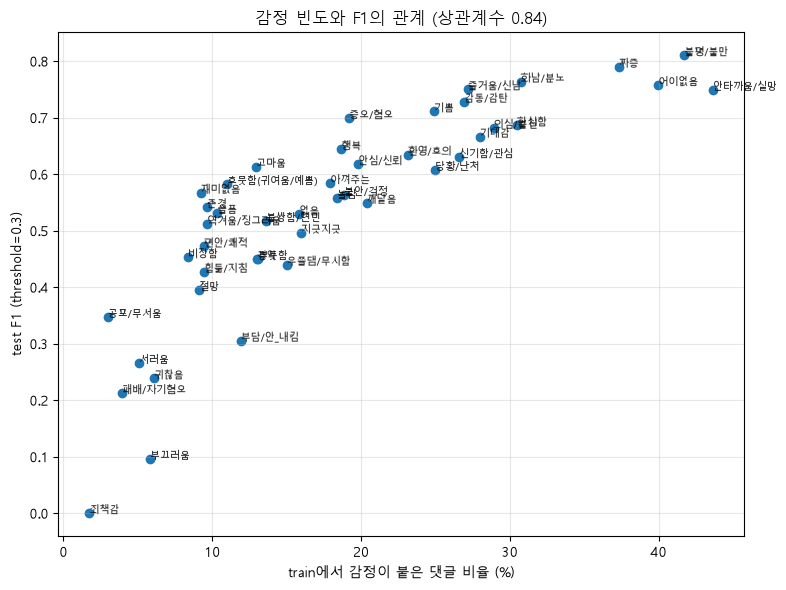

F1 하위 5개: ['죄책감', '부끄러움', '패배/자기혐오', '귀찮음', '서러움']
F1 상위 5개: ['불평/불만', '짜증', '화남/분노', '어이없음', '즐거움/신남']


In [37]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(report_df["train_freq(%)"], report_df["f1-score"])
for name, row in report_df.iterrows():
    ax.annotate(name, (row["train_freq(%)"], row["f1-score"]), fontsize=7, alpha=0.8)

corr = np.corrcoef(report_df["train_freq(%)"], report_df["f1-score"])[0, 1]
ax.set_xlabel("train에서 감정이 붙은 댓글 비율 (%)")
ax.set_ylabel("test F1 (threshold=0.3)")
ax.set_title(f"감정 빈도와 F1의 관계 (상관계수 {corr:.2f})")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("F1 하위 5개:", report_df.index[:5].tolist())
print("F1 상위 5개:", report_df.index[::-1][:5].tolist())

### 4) 비교표: LSTM vs KcBERT vs KcELECTRA
- 같은 데이터 분할(KOTE train/val/test), 같은 정답(44차원 multi-hot), 같은 threshold(0.3)
- KcELECTRA 값은 KOTE 제작자 저장소(github.com/searle-j/KOTE) 값
    - 논문 pytorch_lightning 버전: `codes/KOTE_pytorch_lightning.ipynb`의 classification_report 출력 (macro F1 0.56, micro F1 0.66, 소수점 둘째 자리)
    - Hugging Face Trainer 버전: README에 적힌 macro F1 0.55 (평가 코드/출력이 없어 micro F1은 비워 둠)
- LSTM 값은 과제 1(`01_lstm_from_scratch.ipynb`)의 test 결과 (threshold 0.3)

In [38]:
LSTM_RESULT = {
    "f1_macro": 0.4362,   # 과제 1 test 결과 (threshold 0.3)
    "f1_micro": 0.5514,
    "threshold": 0.3,
}

compare_df = pd.DataFrame([
    {"모델": "전부 예측 (기준선)", "학습 방식": "-",
     "f1_macro": baseline_all["f1_macro"], "f1_micro": baseline_all["f1_micro"], "threshold": "-"},
    {"모델": "LSTM (과제 1)", "학습 방식": "처음부터 학습",
     "f1_macro": LSTM_RESULT["f1_macro"], "f1_micro": LSTM_RESULT["f1_micro"], "threshold": LSTM_RESULT["threshold"]},
    {"모델": "KcBERT (이번 과제)", "학습 방식": "사전학습 + fine-tuning",
     "f1_macro": test_metrics["f1_macro"], "f1_micro": test_metrics["f1_micro"], "threshold": 0.3},
    {"모델": "KcELECTRA (KOTE 제작자)", "학습 방식": "사전학습 + fine-tuning",
     "f1_macro": 0.56, "f1_micro": 0.66, "threshold": 0.3},
    {"모델": "KcELECTRA (제작자 HF Trainer 버전)", "학습 방식": "사전학습 + fine-tuning",
     "f1_macro": 0.55, "f1_micro": None, "threshold": "-"},   # 평가 코드가 없어 threshold 확인 불가
]).set_index("모델")

compare_df.round(4)

,학습 방식,f1_macro,f1_micro,threshold
모델,,,,
전부 예측 (기준선),-,0.2921,0.3054,-
LSTM (과제 1),처음부터 학습,0.4362,0.5514,0.3
KcBERT (이번 과제),사전학습 + fine-tuning,0.5368,0.6361,0.3
KcELECTRA (KOTE 제작자),사전학습 + fine-tuning,0.5600,0.6600,0.3
KcELECTRA (제작자 HF Trainer 버전),사전학습 + fine-tuning,0.5500,NaN,-


### 평가 정리
- KcBERT test macro F1 / micro F1: (작성)
- LSTM 대비: (작성)
- KcELECTRA 대비: (작성 — 과제 2에서 정리한 BERT 방식의 단점과 연결)
- threshold: (val 최적 threshold와 0.3의 차이 작성)
- 희귀 감정: (빈도-F1 그래프 결과 작성)